# ============================================================
# PROJECT: Tomato Leaf Disease Classification
# METHOD: Convolutional Neural Network (CNN)
# EXPERIMENT: 1 — 80:20 Train-Test Split
# ============================================================

## IMPORT LIBRARIES

In [13]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

## CONFIGURATION

In [2]:
DATASET_PATH = "content/dadata"
IMAGE_SIZE = (128, 128)
TEST_SIZE = 0.20
RANDOM_STATE = 42
EPOCHS = 20
BATCH_SIZE = 32

SUPPORTED_FORMATS = (".jpg", ".jpeg", ".png")

# Reproducibility
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_PATH}"
    )

## LOAD AND PREPROCESS DATASET

In [3]:
images = []
labels = []

class_names = sorted(
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
)

print("Classes found:", class_names)

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = sorted(os.listdir(class_path))

    for filename in image_files:
        if not filename.lower().endswith(SUPPORTED_FORMATS):
            continue

        image_path = os.path.join(class_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            print("Warning: Unable to read image:", image_path)
            continue

        image = cv2.resize(image, IMAGE_SIZE)

        images.append(image)
        labels.append(class_name)

if not images:
    raise ValueError("No valid images were found in the dataset.")

X = np.array(images, dtype=np.float32) / 255.0
labels = np.array(labels)

print("\nDataset Summary")
print("Total images:", len(X))
print("Image shape:", X.shape)
print("Number of classes:", len(class_names))

Classes found: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']

Dataset Summary
Total images: 800
Image shape: (800, 128, 128, 3)
Number of classes: 4


## EXPLORE DATASET DISTRIBUTION


Images per class:
Tomato___Bacterial_spot: 200
Tomato___Early_blight: 200
Tomato___Septoria_leaf_spot: 200
Tomato___healthy: 200


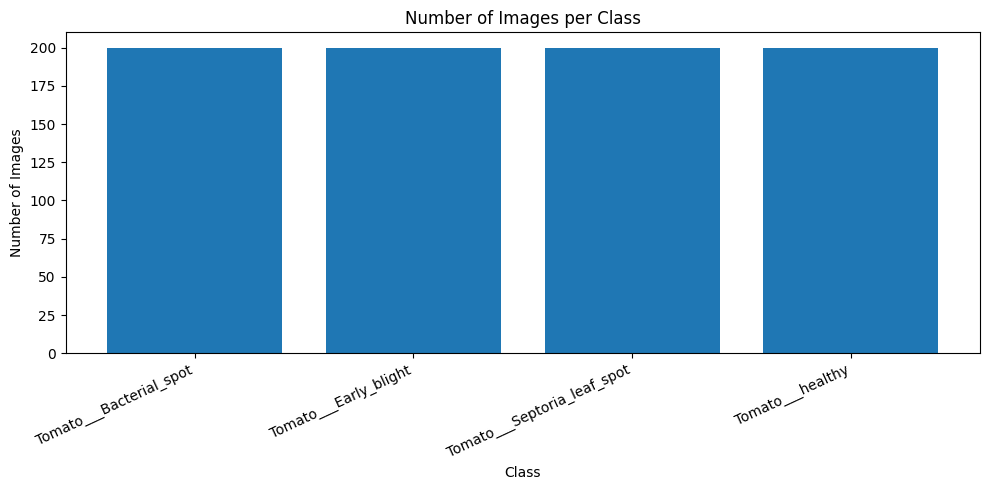

In [4]:
class_counts = {
    class_name: int(np.sum(labels == class_name))
    for class_name in class_names
}

print("\nImages per class:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## DISPLAY SAMPLE IMAGES

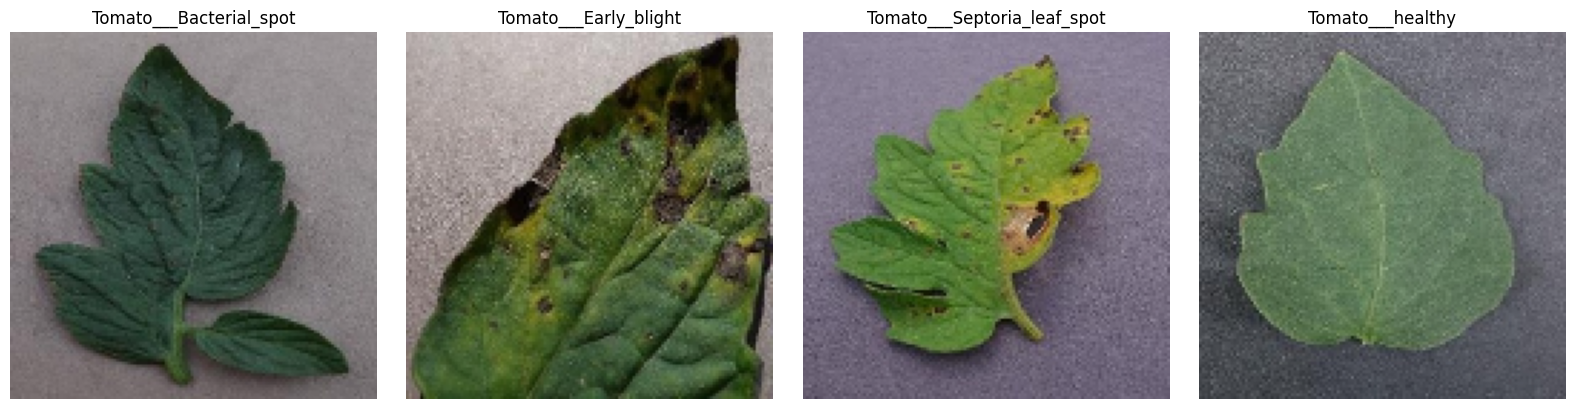

In [5]:
fig, axes = plt.subplots(
    1,
    len(class_names),
    figsize=(4 * len(class_names), 4)
)

axes = np.atleast_1d(axes)

for index, class_name in enumerate(class_names):
    sample_index = np.where(labels == class_name)[0][0]

    # Convert BGR to RGB for correct visualization
    sample_image = cv2.cvtColor(
        (X[sample_index] * 255).astype(np.uint8),
        cv2.COLOR_BGR2RGB
    )

    axes[index].imshow(sample_image)
    axes[index].set_title(class_name)
    axes[index].axis("off")

plt.tight_layout()
plt.show()

## ENCODE CLASS LABELS

In [6]:
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

num_classes = len(label_encoder.classes_)
labels_categorical = to_categorical(
    labels_encoded,
    num_classes=num_classes
)

print("\nClass Mapping:")
for index, class_name in enumerate(label_encoder.classes_):
    print(f"{index}: {class_name}")


Class Mapping:
0: Tomato___Bacterial_spot
1: Tomato___Early_blight
2: Tomato___Septoria_leaf_spot
3: Tomato___healthy


## SPLIT DATASET (80:20)

In [7]:
# Split the dataset into training and test sets (80:20)
X_train_full, X_test, y_train_full, y_test, labels_train_full, labels_test = (
    train_test_split(
        X,
        labels_categorical,
        labels_encoded,
        test_size=0.20,
        random_state=42,
        stratify=labels_encoded
    )
)

# Split the training set into training and validation sets (80:20)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=labels_train_full
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))

Training images: 512
Validation images: 128
Test images: 160


##  VISUALIZATION FUNCTIONS

In [8]:
def plot_training_history(history, model_name):
    """Plot training and validation accuracy and loss."""

    epochs_range = range(1, len(history.history["accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epochs_range,
        history.history["accuracy"],
        label="Training Accuracy"
    )
    axes[0].plot(
        epochs_range,
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(
        epochs_range,
        history.history["loss"],
        label="Training Loss"
    )
    axes[1].plot(
        epochs_range,
        history.history["val_loss"],
        label="Validation Loss"
    )
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


def evaluate_model(model, X_eval, y_eval, model_name):
    """Generate classification metrics and a confusion matrix."""

    probabilities = model.predict(X_eval, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)
    true_labels = np.argmax(y_eval, axis=1)

    class_indices = np.arange(num_classes)
    class_names = label_encoder.classes_

    print(f"\n{model_name} - Classification Report")
    print(
        classification_report(
            true_labels,
            predicted_labels,
            labels=class_indices,
            target_names=class_names,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=class_indices
    )

    print(f"{model_name} - Confusion Matrix")
    print(cm)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    test_loss, test_accuracy = model.evaluate(
        X_eval,
        y_eval,
        verbose=0
    )

    print(f"{model_name} - Test Loss: {test_loss:.4f}")
    print(f"{model_name} - Test Accuracy: {test_accuracy:.2%}")

    return test_loss, test_accuracy

## DEFINE FOUR CNN ARCHITECTURES

In [9]:
def build_model_1():
    model = Sequential([
        Conv2D(
            32, (3, 3),
            activation="relu",
            input_shape=(*IMAGE_SIZE, 3)
        ),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax")
    ])

    return model


def build_model_2():
    model = Sequential([
        Conv2D(
            32, (5, 5),
            activation="relu",
            input_shape=(*IMAGE_SIZE, 3)
        ),
        MaxPooling2D((2, 2)),

        Conv2D(64, (5, 5), activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax")
    ])

    return model


def build_model_3():
    model = Sequential([
        Conv2D(
            64, (3, 3),
            activation="relu",
            input_shape=(*IMAGE_SIZE, 3)
        ),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Flatten(),
        Dense(512, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax")
    ])

    return model


def build_model_4():
    model = Sequential([
        Conv2D(
            32, (3, 3),
            activation="relu",
            input_shape=(*IMAGE_SIZE, 3)
        ),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax")
    ])

    return model

## TRAIN AND EVALUATE FOUR CNN MODELS


Training Model 1


c:\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,836 (28.20 MB)

 Trainable params: 7,392,836 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 334ms/step - accuracy: 0.2767 - loss: 1.7227 - val_accuracy: 0.2500 - val_loss: 1.3514
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 300ms/step - accuracy: 0.3229 - loss: 1.3247 - val_accuracy: 0.6406 - val_loss: 1.2342
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 304ms/step - accuracy: 0.4998 - loss: 1.1671 - val_accuracy: 0.6562 - val_loss: 1.0093
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 306ms/step - accuracy: 0.6255 - loss: 0.9194 - val_accuracy: 0.6016 - val_loss: 0.9266
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 301ms/step - accuracy: 0.6738 - loss: 0.8262 - val_accuracy: 0.7500 - val_loss: 0.7587
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 309ms/step - accuracy: 0.7359 - loss: 0.6622 - val_accuracy: 0.7578 - val_loss: 0.7048
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 311ms/step - accuracy: 0.8191 - loss: 0.4867 - val_accuracy: 0.8125 - val_loss: 0.5667
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 313ms/step - accuracy: 0.8054 - loss: 0.5124 - val_accuracy: 0.

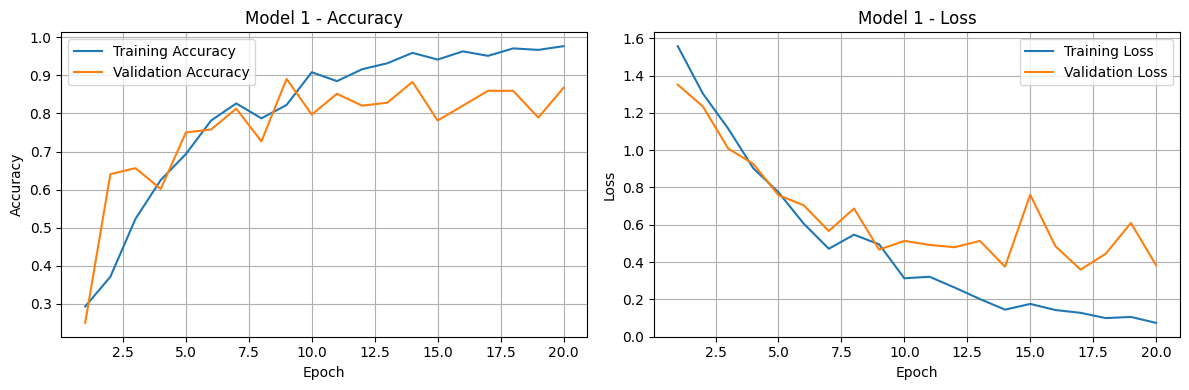


Model 1 - Classification Report
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.97      0.90      0.94        40
      Tomato___Early_blight       0.94      0.85      0.89        40
Tomato___Septoria_leaf_spot       0.90      0.90      0.90        40
           Tomato___healthy       0.83      0.97      0.90        40

                   accuracy                           0.91       160
                  macro avg       0.91      0.91      0.91       160
               weighted avg       0.91      0.91      0.91       160

Model 1 - Confusion Matrix
[[36  1  0  3]
 [ 1 34  3  2]
 [ 0  1 36  3]
 [ 0  0  1 39]]


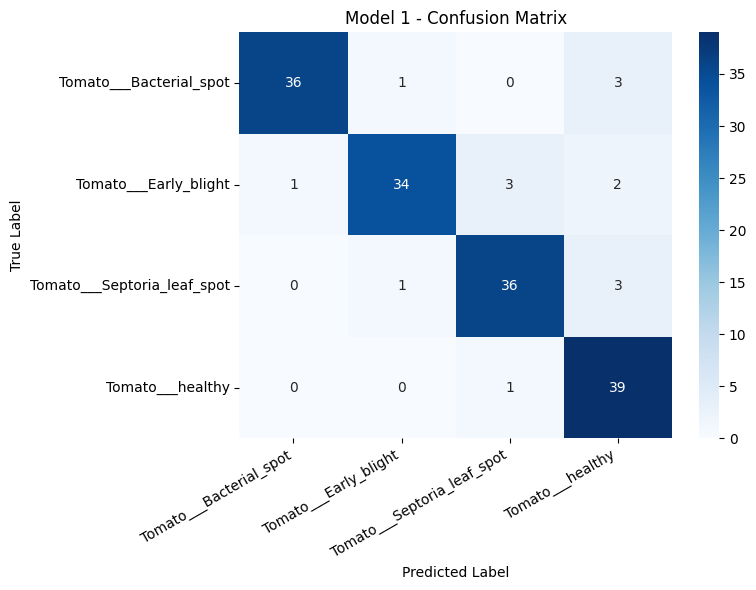

Model 1 - Test Loss: 0.2973
Model 1 - Test Accuracy: 90.62%

Training Model 2


c:\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 124, 124, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 58, 58, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 53824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    13,779,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,833,924 (52.77 MB)

 Trainable params: 13,833,924 (52.77 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 500ms/step - accuracy: 0.2655 - loss: 1.8204 - val_accuracy: 0.3828 - val_loss: 1.3020
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 484ms/step - accuracy: 0.3065 - loss: 1.3261 - val_accuracy: 0.6094 - val_loss: 1.2075
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 482ms/step - accuracy: 0.5053 - loss: 1.1307 - val_accuracy: 0.6250 - val_loss: 0.8544
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 480ms/step - accuracy: 0.6797 - loss: 0.8404 - val_accuracy: 0.6094 - val_loss: 0.9709
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 480ms/step - accuracy: 0.7384 - loss: 0.6776 - val_accuracy: 0.7500 - val_loss: 0.7458
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 481ms/step - accuracy: 0.7361 - loss: 0.6083 - val_accuracy: 0.6641 - val_loss: 0.8936
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 492ms/step - accuracy: 0.8412 - loss: 0.4175 - val_accuracy: 0.7266 - val_loss: 0.6221
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 489ms/step - accuracy: 0.9035 - loss: 0.2900 - val_accuracy: 0

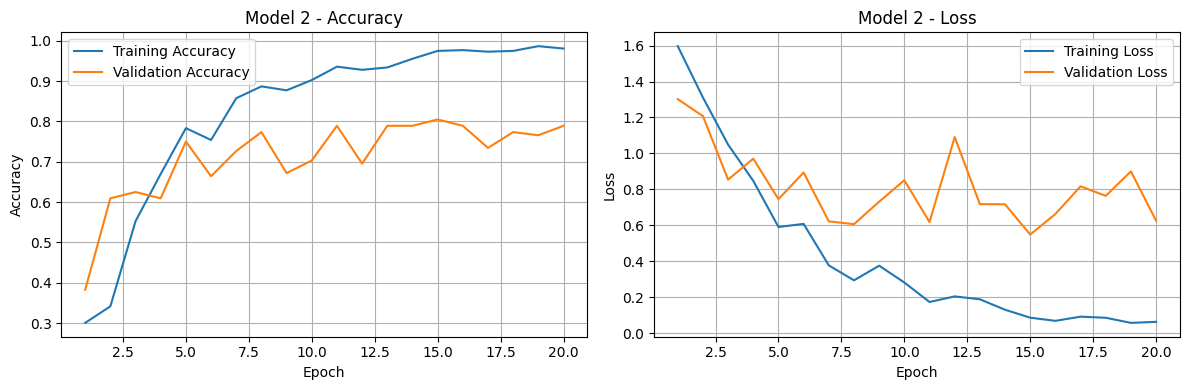


Model 2 - Classification Report
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.78      0.97      0.87        40
      Tomato___Early_blight       0.76      0.62      0.68        40
Tomato___Septoria_leaf_spot       0.72      0.82      0.77        40
           Tomato___healthy       1.00      0.78      0.87        40

                   accuracy                           0.80       160
                  macro avg       0.81      0.80      0.80       160
               weighted avg       0.81      0.80      0.80       160

Model 2 - Confusion Matrix
[[39  0  1  0]
 [11 25  4  0]
 [ 0  7 33  0]
 [ 0  1  8 31]]


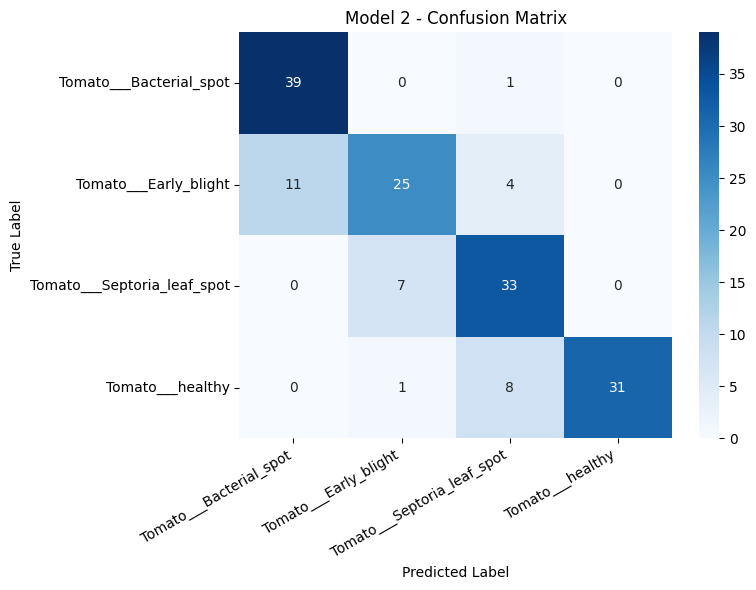

Model 2 - Test Loss: 0.8002
Model 2 - Test Accuracy: 80.00%

Training Model 3


c:\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    58,982,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,060,612 (225.30 MB)

 Trainable params: 59,060,612 (225.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.2306 - loss: 6.0460 - val_accuracy: 0.2266 - val_loss: 1.3632
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.2550 - loss: 1.3816 - val_accuracy: 0.2734 - val_loss: 1.3294
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.3422 - loss: 1.3209 - val_accuracy: 0.5781 - val_loss: 1.2059
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.5279 - loss: 1.1211 - val_accuracy: 0.4922 - val_loss: 1.1711
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.6567 - loss: 0.8952 - val_accuracy: 0.7656 - val_loss: 0.6950
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7674 - loss: 0.6128 - val_accuracy: 0.8125 - val_loss: 0.5330
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8361 - loss: 0.5031 - val_accuracy: 0.8203 - val_loss: 0.5601
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8653 - loss: 0.3871 - val_accuracy: 0.8047 - val_loss:

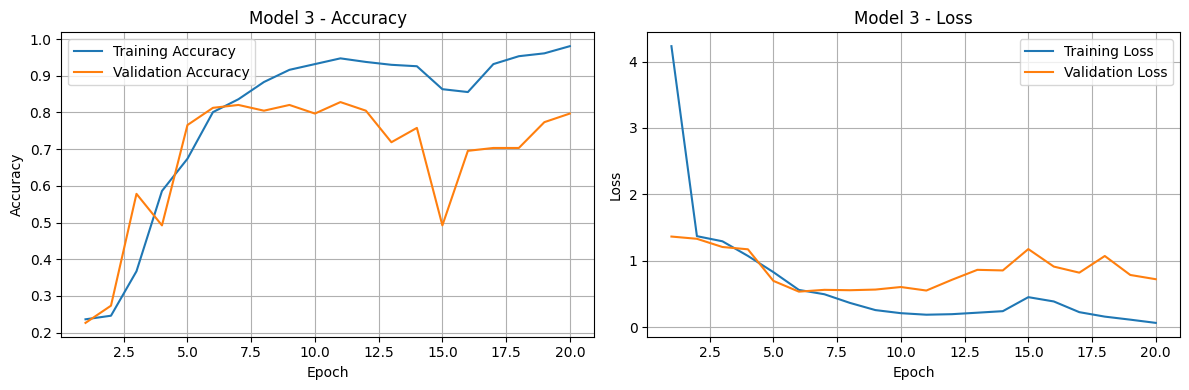


Model 3 - Classification Report
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.95      0.93      0.94        40
      Tomato___Early_blight       0.81      0.85      0.83        40
Tomato___Septoria_leaf_spot       0.78      0.80      0.79        40
           Tomato___healthy       0.84      0.80      0.82        40

                   accuracy                           0.84       160
                  macro avg       0.85      0.84      0.84       160
               weighted avg       0.85      0.84      0.84       160

Model 3 - Confusion Matrix
[[37  2  1  0]
 [ 2 34  1  3]
 [ 0  5 32  3]
 [ 0  1  7 32]]


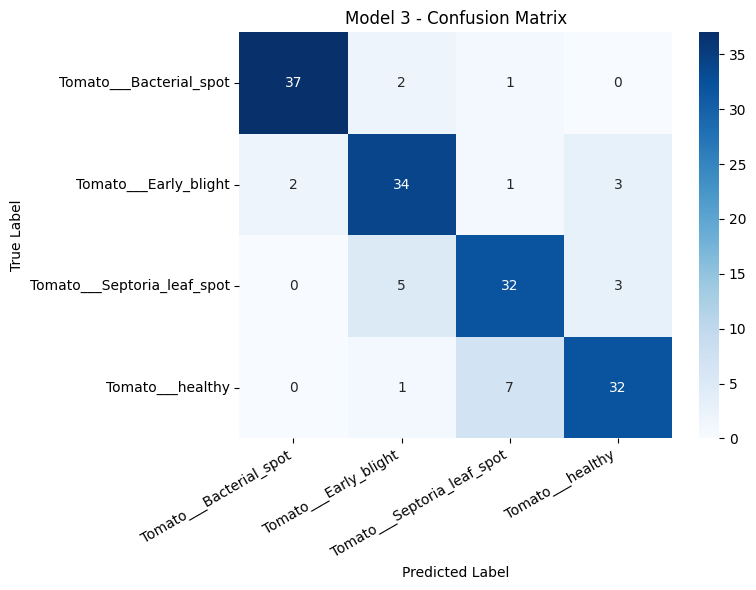

Model 3 - Test Loss: 0.5440
Model 3 - Test Accuracy: 84.38%

Training Model 4


c:\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 363ms/step - accuracy: 0.2385 - loss: 1.4774 - val_accuracy: 0.3203 - val_loss: 1.3515
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 344ms/step - accuracy: 0.3077 - loss: 1.3601 - val_accuracy: 0.4766 - val_loss: 1.1535
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 347ms/step - accuracy: 0.4638 - loss: 1.1392 - val_accuracy: 0.5625 - val_loss: 0.9039
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 336ms/step - accuracy: 0.5938 - loss: 0.9403 - val_accuracy: 0.6406 - val_loss: 0.7768
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 335ms/step - accuracy: 0.7045 - loss: 0.7594 - val_accuracy: 0.7500 - val_loss: 0.6711
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 343ms/step - accuracy: 0.8005 - loss: 0.5972 - val_accuracy: 0.6562 - val_loss: 0.7356
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 336ms/step - accuracy: 0.7660 - loss: 0.5794 - val_accuracy: 0.6484 - val_loss: 0.7296
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 338ms/step - accuracy: 0.7926 - loss: 0.4772 - val_accuracy: 0.

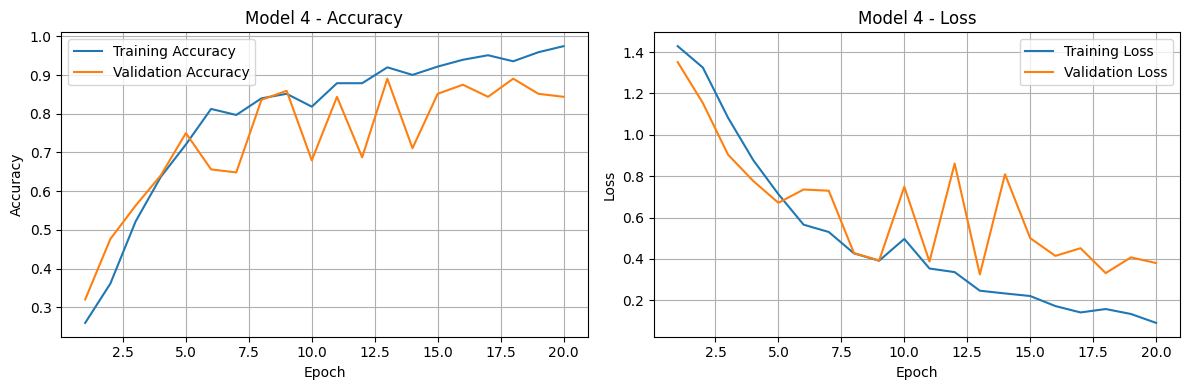


Model 4 - Classification Report
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.78      0.97      0.87        40
      Tomato___Early_blight       0.93      0.65      0.76        40
Tomato___Septoria_leaf_spot       0.88      0.90      0.89        40
           Tomato___healthy       0.90      0.93      0.91        40

                   accuracy                           0.86       160
                  macro avg       0.87      0.86      0.86       160
               weighted avg       0.87      0.86      0.86       160

Model 4 - Confusion Matrix
[[39  0  0  1]
 [11 26  2  1]
 [ 0  2 36  2]
 [ 0  0  3 37]]


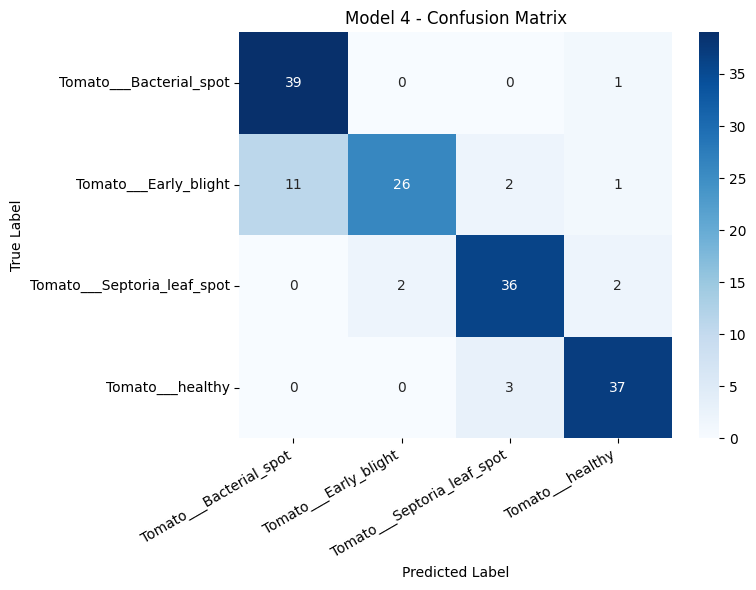

Model 4 - Test Loss: 0.4269
Model 4 - Test Accuracy: 86.25%


In [10]:
model_builders = {
    "Model 1": build_model_1,
    "Model 2": build_model_2,
    "Model 3": build_model_3,
    "Model 4": build_model_4
}

models = {}
histories = {}
evaluation_results = {}

for model_name, build_model in model_builders.items():
    print(f"\n{'=' * 60}")
    print(f"Training {model_name}")
    print("=" * 60)

    model = build_model()

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.summary()

    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        verbose=1
    )

    models[model_name] = model
    histories[model_name] = history

    plot_training_history(history, model_name)

    evaluation_results[model_name] = evaluate_model(
        model,
        X_test,
        y_test,
        model_name
    )

## COMPARE MODEL ACCURACY


Model Accuracy Comparison
Model 1: 90.62%
Model 2: 80.00%
Model 3: 84.38%
Model 4: 86.25%


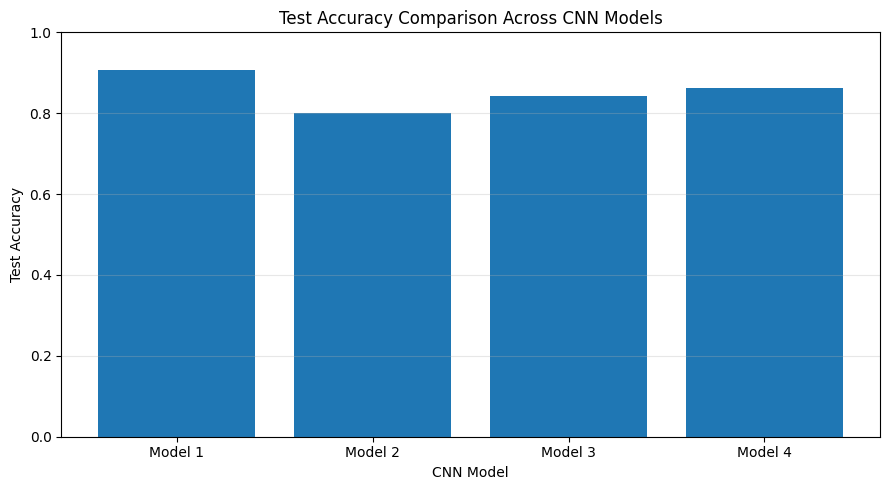

In [11]:
model_names = list(models.keys())
test_accuracies = [
    evaluation_results[name][1]
    for name in model_names
]

print("\nModel Accuracy Comparison")
for name, accuracy in zip(model_names, test_accuracies):
    print(f"{name}: {accuracy:.2%}")

plt.figure(figsize=(9, 5))
plt.bar(model_names, test_accuracies)
plt.title("Test Accuracy Comparison Across CNN Models")
plt.xlabel("CNN Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## PREDICT AN EXTERNAL IMAGE

### EXTERNAL IMAGE TESTING


EXTERNAL IMAGE TESTING MENU
1. Single Image Testing
2. Batch Image Testing (All Images)

Batch Image Testing


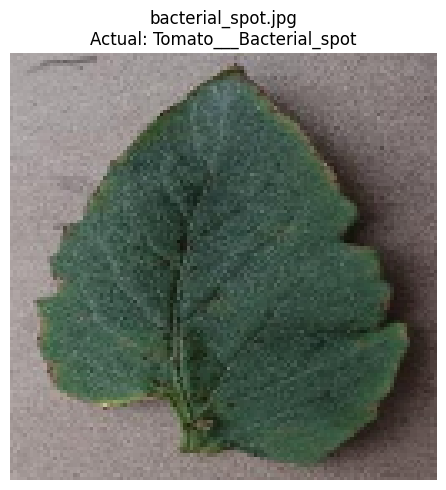


Image: bacterial_spot.jpg
Actual Class: Tomato___Bacterial_spot
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___Bacterial_spot
Confidence: 91.07%
Result: Correct
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___Bacterial_spot
Confidence: 99.63%
Result: Correct
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___Bacterial_spot
Confidence: 96.88%
Result: Correct
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___Bacterial_spot
Confidence: 98.65%
Result: Correct
----------------------------------------------------------------------


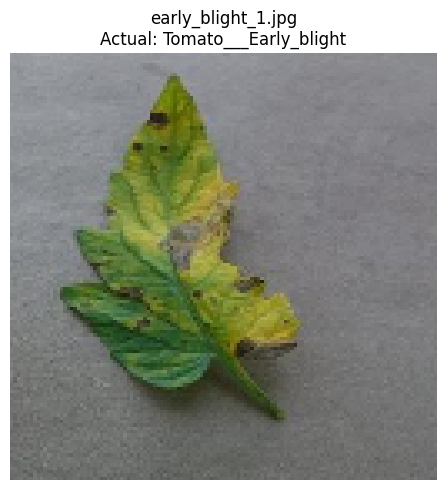


Image: early_blight_1.jpg
Actual Class: Tomato___Early_blight
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___Early_blight
Confidence: 69.42%
Result: Correct
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___Bacterial_spot
Confidence: 49.86%
Result: Incorrect
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___Bacterial_spot
Confidence: 66.23%
Result: Incorrect
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___Bacterial_spot
Confidence: 73.71%
Result: Incorrect
----------------------------------------------------------------------


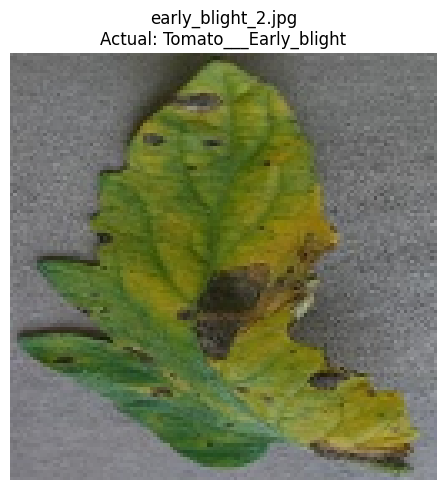


Image: early_blight_2.jpg
Actual Class: Tomato___Early_blight
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___Early_blight
Confidence: 80.05%
Result: Correct
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___Early_blight
Confidence: 79.29%
Result: Correct
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___Early_blight
Confidence: 93.77%
Result: Correct
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___Bacterial_spot
Confidence: 53.03%
Result: Incorrect
----------------------------------------------------------------------


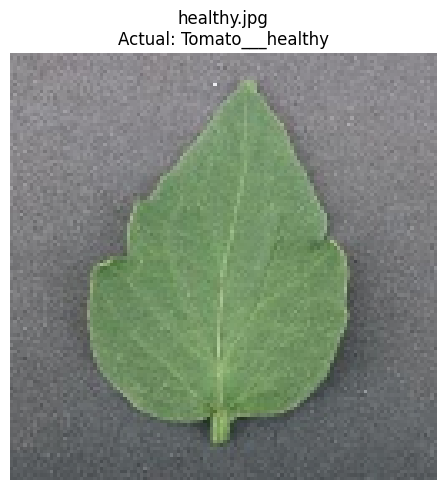


Image: healthy.jpg
Actual Class: Tomato___healthy
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___healthy
Confidence: 99.59%
Result: Correct
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___healthy
Confidence: 95.73%
Result: Correct
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___healthy
Confidence: 86.77%
Result: Correct
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___healthy
Confidence: 99.72%
Result: Correct
----------------------------------------------------------------------


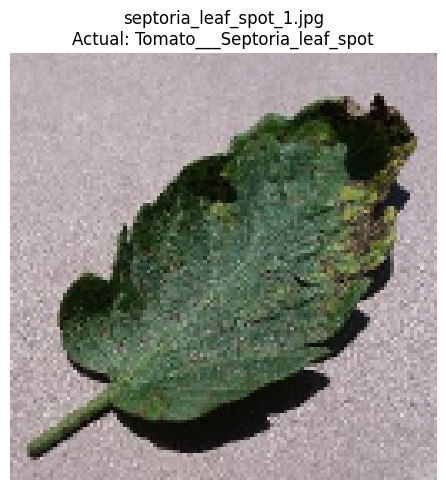


Image: septoria_leaf_spot_1.jpg
Actual Class: Tomato___Septoria_leaf_spot
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 99.91%
Result: Correct
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 100.00%
Result: Correct
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 100.00%
Result: Correct
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 99.99%
Result: Correct
----------------------------------------------------------------------


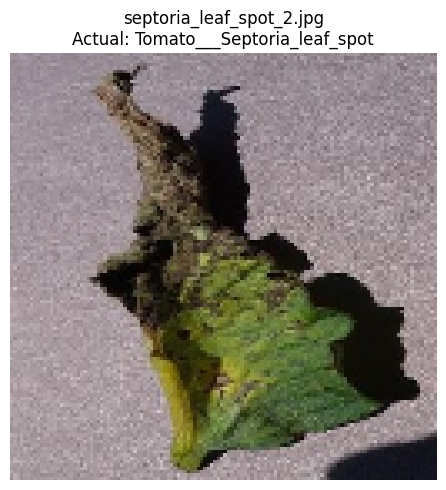


Image: septoria_leaf_spot_2.jpg
Actual Class: Tomato___Septoria_leaf_spot
----------------------------------------------------------------------
Model: Model 1
Predicted Class: Tomato___healthy
Confidence: 80.01%
Result: Incorrect
----------------------------------------------------------------------
Model: Model 2
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 84.87%
Result: Correct
----------------------------------------------------------------------
Model: Model 3
Predicted Class: Tomato___Early_blight
Confidence: 99.97%
Result: Incorrect
----------------------------------------------------------------------
Model: Model 4
Predicted Class: Tomato___Septoria_leaf_spot
Confidence: 68.84%
Result: Correct
----------------------------------------------------------------------

Detailed Prediction Results
                   Image   Model                Actual Class             Predicted Class Confidence    Result
      bacterial_spot.jpg Model 1     Tomato___Bacterial_spot    

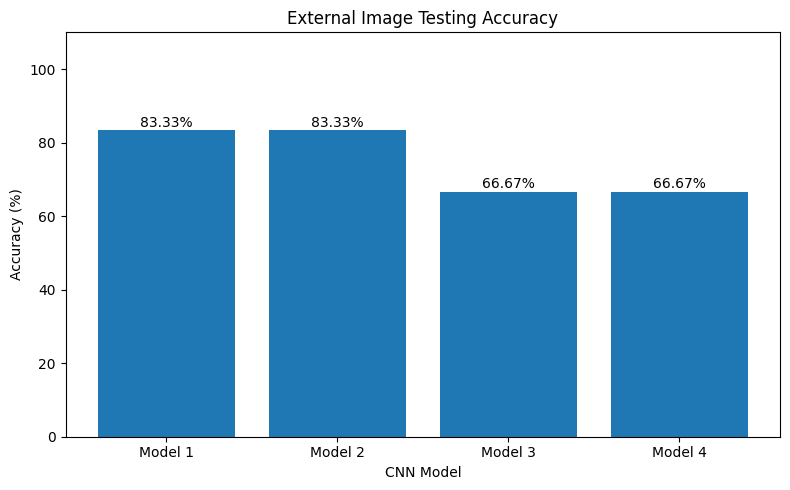


Results saved to:
- external_image_predictions.csv
- external_image_model_summary.csv


In [ ]:

EXTERNAL_TEST_DIR = "content/uji"

# Map image filenames to their actual class labels
external_test_images = {
    "bacterial_spot.jpg": "Tomato___Bacterial_spot",
    "early_blight_1.jpg": "Tomato___Early_blight",
    "early_blight_2.jpg": "Tomato___Early_blight",
    "healthy.jpg": "Tomato___healthy",
    "septoria_leaf_spot_1.jpg": "Tomato___Septoria_leaf_spot",
    "septoria_leaf_spot_2.jpg": "Tomato___Septoria_leaf_spot"
}

# Available CNN models
model_names = list(models.keys())


def load_external_image(image_name):
    """Load and preprocess one external image."""
    image_path = os.path.join(EXTERNAL_TEST_DIR, image_name)

    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    resized_image = cv2.resize(image, IMAGE_SIZE)
    image_array = resized_image.astype(np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    display_image = cv2.cvtColor(
        resized_image, cv2.COLOR_BGR2RGB
    )

    return image_array, display_image


def predict_image(image_array, true_class):
    """Generate predictions from all CNN models."""
    results = []

    for model_name, model in models.items():
        probabilities = model.predict(image_array, verbose=0)[0]

        predicted_index = int(np.argmax(probabilities))
        predicted_class = label_encoder.inverse_transform(
            [predicted_index]
        )[0]

        confidence = float(probabilities[predicted_index])
        correct = predicted_class == true_class

        results.append({
            "Model": model_name,
            "Predicted Class": predicted_class,
            "Confidence": confidence,
            "Actual Class": true_class,
            "Result": "Correct" if correct else "Incorrect"
        })

    return results


def single_image_testing():
    """Test one image selected by the user."""
    image_names = list(external_test_images.keys())

    print("\nAvailable External Test Images")
    print("=" * 70)

    for index, image_name in enumerate(image_names, start=1):
        print(
            f"{index}. {image_name} | "
            f"Actual Class: {external_test_images[image_name]}"
        )

    try:
        image_number = int(input("\nSelect image number (1-6): "))
    except ValueError:
        print("Invalid input. Please enter a number.")
        return

    if not 1 <= image_number <= len(image_names):
        print(f"Please select a number from 1 to {len(image_names)}.")
        return

    image_name = image_names[image_number - 1]
    true_class = external_test_images[image_name]

    try:
        image_array, display_image = load_external_image(image_name)
    except (FileNotFoundError, ValueError) as error:
        print(error)
        return

    plt.figure(figsize=(5, 5))
    plt.imshow(display_image)
    plt.title(f"{image_name}\nActual: {true_class}")
    plt.axis("off")
    plt.show()

    results = predict_image(image_array, true_class)

    print("\nSingle Image Prediction Results")
    print("=" * 70)
    print(f"Image: {image_name}")
    print(f"Actual Class: {true_class}")
    print("-" * 70)

    for result in results:
        print(f"Model: {result['Model']}")
        print(f"Predicted Class: {result['Predicted Class']}")
        print(f"Confidence: {result['Confidence']:.2%}")
        print(f"Result: {result['Result']}")
        print("-" * 70)


def batch_image_testing():
    """Test all external images and display each image with predictions."""
    all_results = []

    print("\nBatch Image Testing")
    print("=" * 70)

    for image_name, true_class in external_test_images.items():
        try:
            image_array, display_image = load_external_image(image_name)
        except (FileNotFoundError, ValueError) as error:
            print(f"Skipping {image_name}: {error}")
            continue

        # Generate predictions using all CNN models
        predictions = predict_image(image_array, true_class)

        for result in predictions:
            result["Image"] = image_name
            all_results.append(result)

        # Display the current image
        plt.figure(figsize=(5, 5))
        plt.imshow(display_image)
        plt.title(f"{image_name}\nActual: {true_class}")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

        # Display prediction results for this image
        print(f"\nImage: {image_name}")
        print(f"Actual Class: {true_class}")
        print("-" * 70)

        for result in predictions:
            print(f"Model: {result['Model']}")
            print(f"Predicted Class: {result['Predicted Class']}")
            print(f"Confidence: {result['Confidence']:.2%}")
            print(f"Result: {result['Result']}")
            print("-" * 70)

    if not all_results:
        print("No images were successfully tested.")
        return

    # Create detailed results table
    results_df = pd.DataFrame(all_results)

    display_df = results_df.copy()
    display_df["Confidence"] = (
        display_df["Confidence"] * 100
    ).round(2).astype(str) + "%"

    print("\nDetailed Prediction Results")
    print("=" * 70)
    print(display_df[
        [
            "Image",
            "Model",
            "Actual Class",
            "Predicted Class",
            "Confidence",
            "Result"
        ]
    ].to_string(index=False))

    # Calculate accuracy for each model
    summary_rows = []

    for model_name in model_names:
        model_results = [
            result for result in all_results
            if result["Model"] == model_name
        ]

        total = len(model_results)
        correct = sum(
            result["Result"] == "Correct"
            for result in model_results
        )

        accuracy = correct / total * 100 if total > 0 else 0

        summary_rows.append({
            "Model": model_name,
            "Correct": correct,
            "Incorrect": total - correct,
            "Total Images": total,
            "Accuracy (%)": round(accuracy, 2)
        })

    summary_df = pd.DataFrame(summary_rows)

    print("\nModel Performance Summary")
    print("=" * 70)
    print(summary_df.to_string(index=False))

    # Visualize model accuracy on external images
    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        summary_df["Model"],
        summary_df["Accuracy (%)"]
    )

    plt.title("External Image Testing Accuracy")
    plt.xlabel("CNN Model")
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, 110)

    for bar, accuracy in zip(
        bars, summary_df["Accuracy (%)"]
    ):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{accuracy:.2f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()

    # Save detailed and summary results
    results_df.to_csv(
        "outputs/external_image_predictions.csv",
        index=False
    )

    summary_df.to_csv(
        "outputs/external_image_model_summary.csv",
        index=False
    )

    print("\nResults saved to:")
    print("- outputs/external_image_predictions.csv")
    print("- outputs/external_image_model_summary.csv")


# Select external image testing mode
print("\nEXTERNAL IMAGE TESTING MENU")
print("=" * 40)
print("1. Single Image Testing")
print("2. Batch Image Testing (All Images)")

try:
    testing_mode = input("Select testing mode (1 or 2): ").strip()

    if testing_mode == "1":
        single_image_testing()
    elif testing_mode == "2":
        batch_image_testing()
    else:
        print("Invalid selection. Please choose 1 or 2.")

except KeyboardInterrupt:
    print("\nTesting cancelled by user.")


## SAVE TRAINED MODELS (OPTIONAL)

In [14]:
# Uncomment this section to save the trained models.
#
# for model_name, model in models.items():
#     filename = model_name.lower().replace(" ", "_") + ".keras"
#     model.save(filename)
#     print(f"Saved {model_name} to {filename}")

print("\nExperiment 1 completed.")



Experiment 1 completed.
